### Uses X_train_scaled.csv and X_test_scaled.csv (neural networks need scaled inputs)
### Keras feedforward network: ReLU hidden layers, 1 sigmoid output, binary cross-entropy
### Uses class_weight = "balanced" to battle class imbalance
### Stratified 20% validation set from train for early stopping, tuning and the threshold
### Grid search over network size, dropout and optimizer, scored by validation PR-AUC
### Test set touched once at the very end
### The final section makes one slide: metrics (train / validation / test), confusion matrix, ROC, tuning, over/underfitting check

In [1]:
from pathlib import Path
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # suppress info and warning messages
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             precision_recall_curve, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
import tensorflow.keras as keras

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
QUICK = False  # True = 8,000 training rows + small grid, just to check everything runs
EPOCHS = 10 if QUICK else 100  # upper limit, early stopping usually ends training well before this
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

#finds data/processed from models/, the repo root, or the D: drive clone
def find_data_dir():
    here = Path.cwd().resolve()
    candidates = [p / "data" / "processed" for p in [here, *here.parents]]
    candidates.append(Path(r"D:\GitHub\Forecasting_Commercial_Success_of_a_SteamGame_using_MachineLearning\data\processed"))
    for c in candidates:
        if (c / "X_train_scaled.csv").exists():
            return c
    raise FileNotFoundError("Could not find data/processed/X_train_scaled.csv, run preprocessing.ipynb first")

DATA_DIR = find_data_dir()

### Loading scaled data and making sure everything matches up

In [2]:
X_full = pd.read_csv(DATA_DIR / "X_train_scaled.csv").astype(float)
X_test = pd.read_csv(DATA_DIR / "X_test_scaled.csv").astype(float)
y_full = pd.read_csv(DATA_DIR / "y_train.csv")["hit"].astype(float)
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["hit"].astype(float)
assert list(X_full.columns) == list(X_test.columns)
assert len(X_full) == len(y_full) and len(X_test) == len(y_test)
assert X_full.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
if QUICK:
    X_full, _, y_full, _ = train_test_split(X_full, y_full, train_size=8000, stratify=y_full, random_state=RANDOM_STATE)

#stratified validation set (validation_split would just take the last 20% of rows without shuffling)
X_train, X_val, y_train, y_val = train_test_split(X_full, y_full, test_size=0.2, stratify=y_full, random_state=RANDOM_STATE)
print(f"Train {X_train.shape}, Validation {X_val.shape}, Test {X_test.shape}")
print(f"Hit rate: Train {y_train.mean():.1%}, Validation {y_val.mean():.1%}, Test {y_test.mean():.1%}")

weights = compute_class_weight("balanced", classes=np.array([0.0, 1.0]), y=y_train)
CLASS_WEIGHT = {0: weights[0], 1: weights[1]}
print("Class weights:", {k: round(v, 2) for k, v in CLASS_WEIGHT.items()})

Train (36392, 25), Validation (9099, 25), Test (21760, 25)
Hit rate: Train 10.9%, Validation 10.9%, Test 5.6%
Class weights: {0: np.float64(0.56), 1: np.float64(4.58)}


### Helper functions

In [3]:
#input layer -> Dense hidden layers (ReLU, optional dropout) -> 1 sigmoid output
def build_model(hidden=(64, 32, 16), dropout=0.0, optimizer="adam"):
    keras.utils.set_random_seed(RANDOM_STATE)
    model = keras.Sequential()
    model.add(keras.layers.InputLayer(shape=(X_train.shape[1],)))
    for units in hidden:
        model.add(keras.layers.Dense(units=units, activation="relu", kernel_initializer="he_normal"))
        if dropout:
            model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(units=1, activation="sigmoid"))
    model.compile(optimizer=optimizer, loss=keras.losses.BinaryCrossentropy(from_logits=False),
                  metrics=["accuracy", keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

OPTIMIZERS = {
    "SGD (lr 0.1)":  lambda: keras.optimizers.SGD(learning_rate=0.1),
    "SGD (lr 0.01)": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "Adam (lr 0.001)": lambda: keras.optimizers.Adam(learning_rate=0.001),
}

#early stopping (best weights restored) + halve the learning rate when validation loss stalls
def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]

def predict(model, X):
    return model.predict(X, verbose=0).flatten()

#finds the threshold with the highest F1 on these predictions
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2*prec*rec/np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return f1[i], thr[i]

def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p)}

## Hyperparameter tuning
Every setting is trained with class weights, early stopping and ReduceLROnPlateau, then scored by validation PR-AUC
- hidden layers: network size
- dropout: randomly turns off neurons while training to fight overfitting
- optimizer: plain SGD at two learning rates vs Adam

In [4]:
GRID = {"hidden": [(64, 32)] if QUICK else [(32,), (64, 32), (64, 32, 16), (128, 64, 32)],
        "dropout": [0.0, 0.2] if QUICK else [0.0, 0.2, 0.4],
        "optimizer": ["Adam (lr 0.001)"] if QUICK else list(OPTIMIZERS)}

rows, t0 = [], time.time()
for h in GRID["hidden"]:
    for d in GRID["dropout"]:
        for opt in GRID["optimizer"]:
            m = build_model(hidden=h, dropout=d, optimizer=OPTIMIZERS[opt]())
            hist = m.fit(X_train, y_train, batch_size=128, epochs=EPOCHS, verbose=0, class_weight=CLASS_WEIGHT,
                         validation_data=(X_val, y_val), callbacks=callbacks())
            rows.append({"hidden": "-".join(map(str, h)), "dropout": d, "optimizer": opt,
                         "epochs run": len(hist.history["loss"]),
                         "train PR-AUC": average_precision_score(y_train, predict(m, X_train)),
                         "val PR-AUC": average_precision_score(y_val, predict(m, X_val))})
search = pd.DataFrame(rows).sort_values("val PR-AUC", ascending=False).reset_index(drop=True)
search["gap"] = search["train PR-AUC"] - search["val PR-AUC"]
print(f"{len(search)} settings in {time.time() - t0:.0f}s")
search.head(10).round(4)

36 settings in 1161s


,hidden,dropout,optimizer,epochs run,train PR-AUC,val PR-AUC,gap
0,64-32,0.0,SGD (lr 0.1),76,0.5774,0.5564,0.0210
1,64-32-16,0.0,SGD (lr 0.1),66,0.5718,0.5552,0.0166
2,128-64-32,0.2,Adam (lr 0.001),35,0.5767,0.5530,0.0238
3,128-64-32,0.4,Adam (lr 0.001),37,0.5567,0.5529,0.0038
4,64-32-16,0.2,Adam (lr 0.001),35,0.5549,0.5522,0.0027
5,32,0.0,SGD (lr 0.1),87,0.5605,0.5517,0.0088
6,64-32,0.0,SGD (lr 0.01),100,0.5624,0.5516,0.0108
7,64-32,0.2,Adam (lr 0.001),42,0.5601,0.5499,0.0102
8,64-32,0.0,Adam (lr 0.001),100,0.6030,0.5489,0.0541
9,64-32,0.2,SGD (lr 0.1),68,0.5516,0.5482,0.0034


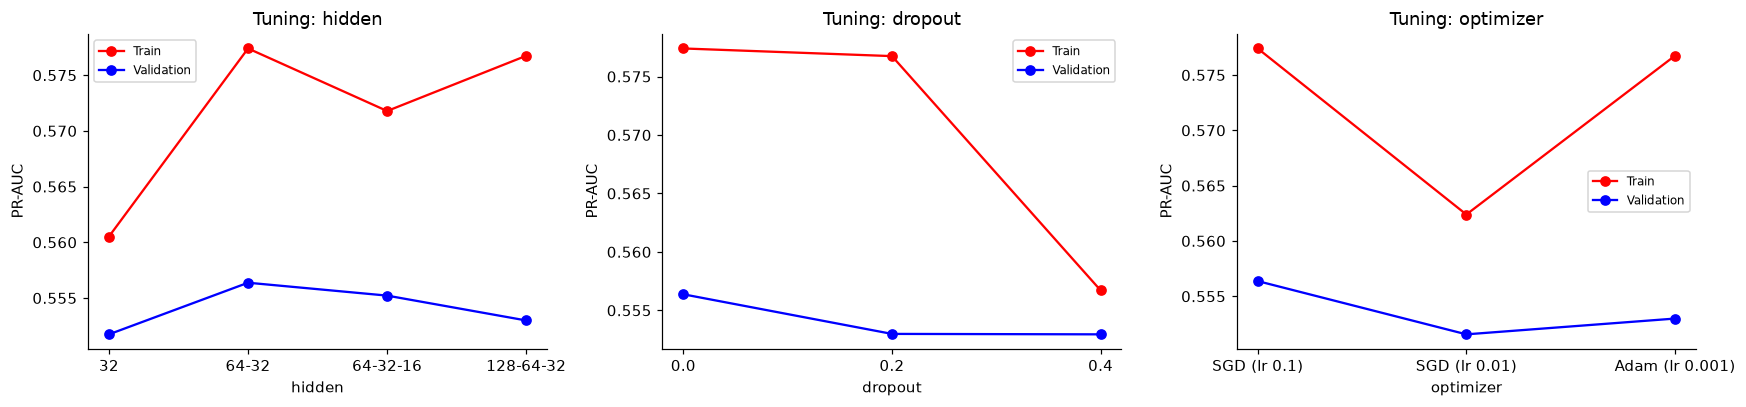

In [5]:
#best train vs validation score for each value of each hyperparameter
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, ["hidden", "dropout", "optimizer"]):
    best_rows = search.loc[search.groupby(col)["val PR-AUC"].idxmax()].set_index(col)
    best_rows = best_rows.loc[[("-".join(map(str, v)) if col == "hidden" else v) for v in GRID[col]]]
    x = [str(v) for v in best_rows.index]
    ax.plot(x, best_rows["train PR-AUC"], marker="o", color="red", label="Train")
    ax.plot(x, best_rows["val PR-AUC"], marker="o", color="blue", label="Validation")
    ax.set(xlabel=col, ylabel="PR-AUC", title=f"Tuning: {col}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Training the best network

In [6]:
best = search.iloc[0]
BEST = {"hidden": tuple(int(x) for x in best["hidden"].split("-")), "dropout": float(best["dropout"]), "optimizer": best["optimizer"]}
print("Best parameters:", BEST)

model = build_model(hidden=BEST["hidden"], dropout=BEST["dropout"], optimizer=OPTIMIZERS[BEST["optimizer"]]())
model.summary()
t0 = time.time()
history = model.fit(X_train, y_train, batch_size=128, epochs=EPOCHS, verbose=0, class_weight=CLASS_WEIGHT,
                    validation_data=(X_val, y_val), callbacks=callbacks())
print(f"Trained {len(history.history['loss'])} epochs in {time.time() - t0:.0f}s, "
      f"best epoch {int(np.argmin(history.history['val_loss'])) + 1} (weights restored from there)")

Best parameters: {'hidden': (64, 32), 'dropout': 0.0, 'optimizer': 'SGD (lr 0.1)'}


Model: "sequential_36"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_117 (Dense)                    │ (None, 64)                  │           1,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_118 (Dense)                    │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_119 (Dense)                    │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,777 (14.75 KB)

 Trainable params: 3,777 (14.75 KB)

 Non-trainable params: 0 (0.00 B)

Trained 76 epochs in 46s, best epoch 71 (weights restored from there)


### Checking for overfitting/underfitting

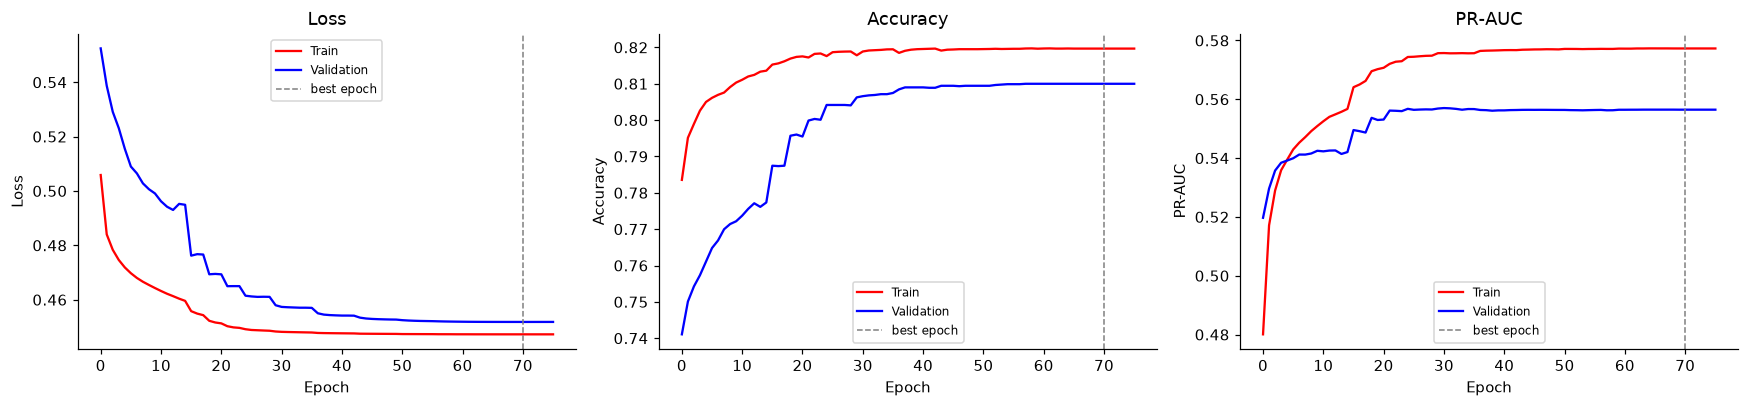

In [7]:
h = history.history
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, key, label in zip(axes, ["loss", "accuracy", "pr_auc"], ["Loss", "Accuracy", "PR-AUC"]):
    ax.plot(h[key], color="red", label="Train")
    ax.plot(h[f"val_{key}"], color="blue", label="Validation")
    ax.axvline(int(np.argmin(h["val_loss"])), color="gray", ls="--", lw=1, label="best epoch")
    ax.set(xlabel="Epoch", ylabel=label, title=label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Early stopping keeps the weights from the epoch with the lowest validation loss, before the validation curve starts going back up (red pulling away from blue = overfitting)

## Neural Network slide
Threshold picked on the validation set, test set used once

===== Neural Network =====
Grid searched: {'hidden': ['(32,)', '(64, 32)', '(64, 32, 16)', '(128, 64, 32)'], 'dropout': ['0.0', '0.2', '0.4'], 'optimizer': ['SGD (lr 0.1)', 'SGD (lr 0.01)', 'Adam (lr 0.001)']}
Best parameters: {'hidden': (64, 32), 'dropout': 0.0, 'optimizer': 'SGD (lr 0.1)'}
Threshold (validation F1-optimal): 0.740


,accuracy,precision,recall,F1,PR-AUC,ROC-AUC
Train,0.898,0.532,0.565,0.548,0.577,0.871
Validation,0.897,0.526,0.556,0.540,0.556,0.843
Test,0.910,0.332,0.596,0.426,0.417,0.850


Random guesser: Test PR-AUC 0.056     F1 0.106


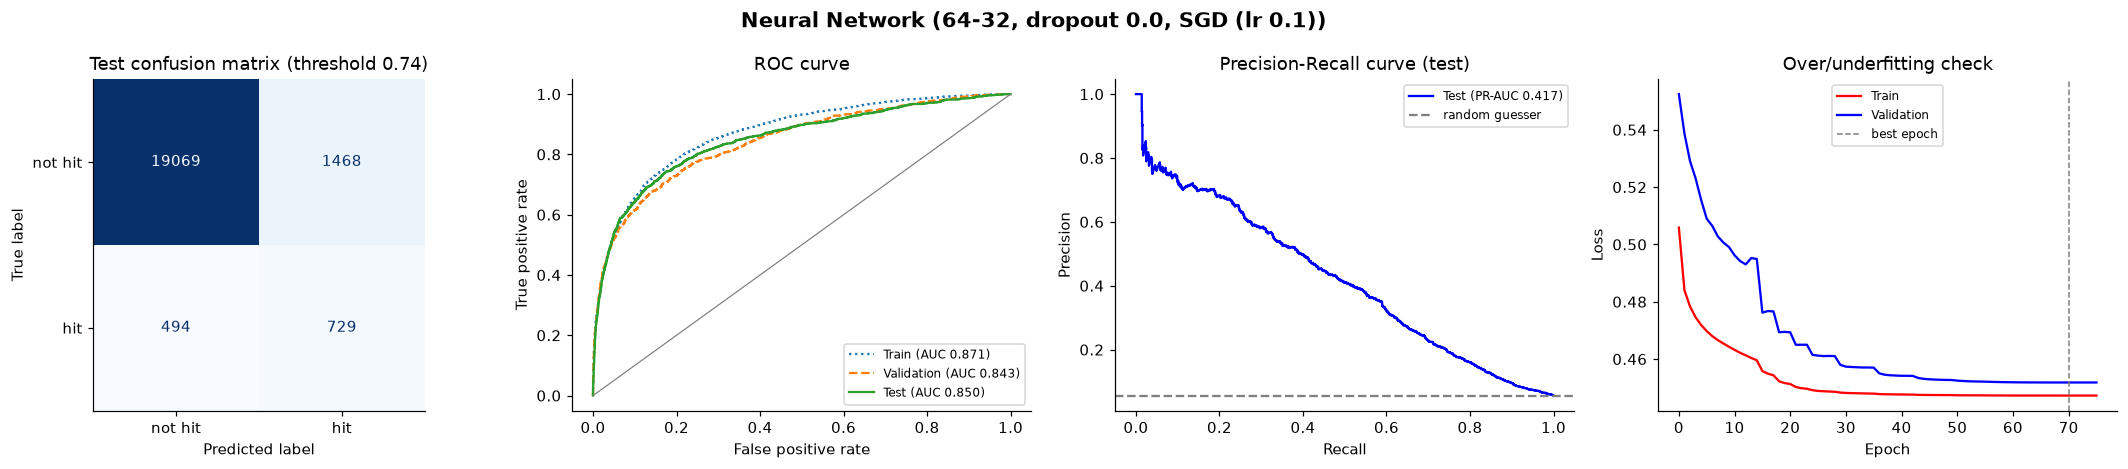

In [8]:
p_train, p_val, p_test = predict(model, X_train), predict(model, X_val), predict(model, X_test)
_, thr = best_f1_threshold(y_val, p_val)

print("===== Neural Network =====")
print("Grid searched:", {k: [str(v) for v in vals] for k, vals in GRID.items()})
print("Best parameters:", BEST)
print(f"Threshold (validation F1-optimal): {thr:.3f}")
table = pd.DataFrame({"Train": metrics(y_train, p_train, thr), "Validation": metrics(y_val, p_val, thr),
                      "Test": metrics(y_test, p_test, thr)}).T
display(table.round(3))
print(f"Random guesser: Test PR-AUC {y_test.mean():.3f}     F1 {2 * y_test.mean() / (1 + y_test.mean()):.3f}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= thr).astype(int)), display_labels=["not hit", "hit"]).plot(ax=axes[0], colorbar=False, cmap="Blues", values_format="d")
axes[0].set_title(f"Test confusion matrix (threshold {thr:.2f})")
axes[0].grid(False)

for y, p, label, style in [(y_train, p_train, "Train", ":"), (y_val, p_val, "Validation", "--"), (y_test, p_test, "Test", "-")]:
    fpr, tpr, _ = roc_curve(y, p)
    axes[1].plot(fpr, tpr, ls=style, label=f"{label} (AUC {roc_auc_score(y, p):.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", lw=0.8)
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[1].legend(fontsize=8)

prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[2].plot(rec, prec, color="blue", label=f"Test (PR-AUC {average_precision_score(y_test, p_test):.3f})")
axes[2].axhline(y_test.mean(), color="gray", ls="--", label="random guesser")
axes[2].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve (test)")
axes[2].legend(fontsize=8)

axes[3].plot(h["loss"], color="red", label="Train")
axes[3].plot(h["val_loss"], color="blue", label="Validation")
axes[3].axvline(int(np.argmin(h["val_loss"])), color="gray", ls="--", lw=1, label="best epoch")
axes[3].set(xlabel="Epoch", ylabel="Loss", title="Over/underfitting check")
axes[3].legend(fontsize=8)
fig.suptitle(f"Neural Network ({best['hidden']}, dropout {BEST['dropout']}, {BEST['optimizer']})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()